# 04. Spatial distribution around genes

Describe environmental association signals and genomic features around transcription start sites (TSSs) and transcription termination sites (TTSs). Single-gene examples explain relative association signal intensity (RASI) before gene-set profiles are examined.


# 04. 基因周围的空间分布

描述转录起始位点（TSS）和转录终止位点（TTS）周围的环境关联信号及基因组特征。先通过单基因示例说明相对关联信号强度（RASI），再考察基因集合的空间分布。


In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import socket
import sys
import yaml
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

with open('config/project.yaml') as handle:
    project_config = yaml.safe_load(handle)
project_dir = project_config['remote']['project_root']
if os.path.realpath(os.getcwd()) != os.path.realpath(project_dir):
    raise ValueError(f'Working directory {os.getcwd()} must match configured project root {project_dir}.')
if project_dir not in sys.path:
    sys.path.insert(0, project_dir)
data_dir = f'{project_dir}/data'
source_dir = f'{data_dir}/source'
results_dir = f'{data_dir}/results'
run_dir = f'{project_dir}/run'
sd_dir = f'{results_dir}/spatial_distribution'
gwas_dir = f'{results_dir}/gwas'

from src.plot import set_plot_style
set_plot_style()
print(f'Host: {socket.gethostname()}')
print(f'Working directory: {os.getcwd()}')
print(f'Python: {sys.executable}')


Host: rock01.local
Working directory: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum
Python: /lustre/home/dobby/Program/agent_program/micromamba-root/envs/dobby-base/bin/python


## 1. Relative association signal intensity

For each TSS or TTS, summarize raw association P values in 500 bp windows advanced in 10 bp steps across the region from anchor −10 kb through anchor +10 kb −1 bp. Define relative association signal intensity using the 25th percentile of raw P values:

$$\mathrm{RASI}_w=\frac{-\log_{10}[Q_{25}(P_i\mid i\in w)]}{-\log_{10}[Q_{25}(P_i\mid i\in R)]}.$$

Here $w$ is a window and $R$ is the complete anchor region. Windows with fewer than four variants use the regional percentile, giving RASI=1; regions with fewer than four variants have RASI=1 throughout. Windows follow transcription direction, including the final clipped window. Plot positions use the original relative window coordinate plus 250 bp. Association results use QC variants with MAF ≥0.05 and heterozygosity ≤0.05.


## 1. 相对关联信号强度

在每个TSS或TTS的锚点−10 kb至锚点+10 kb−1 bp区域内，采用500 bp窗口、10 bp步长汇总原始关联P值。使用原始P值的第25百分位数定义相对关联信号强度：

$$\mathrm{RASI}_w=\frac{-\log_{10}[Q_{25}(P_i\mid i\in w)]}{-\log_{10}[Q_{25}(P_i\mid i\in R)]}.$$

其中$w$为窗口，$R$为整个锚点区域。少于四个位点的窗口使用区域百分位数，因此RASI=1；少于四个位点的区域，其所有窗口RASI均为1。窗口沿转录方向排列，包含末端截短窗口；绘图位置沿用原相对窗口坐标加250 bp的口径。关联结果采用MAF ≥0.05、杂合率 ≤0.05的质控变异。


RASI >1 indicates stronger window association intensity than the regional reference; RASI <1 indicates weaker intensity. Enrichment and depletion are assessed relative to random gene-set distributions. If the regional transformed percentile is zero, the ratio is undefined.


RASI >1表示窗口关联信号强于区域参照，RASI <1表示信号较弱。富集与缺失通过随机基因集合的分布判断；区域百分位数变换后的值为零时，比值未定义。


### Worked examples: ELF3 and LWD1

Use the growing-season-length associations at ELF3 and LWD1 to illustrate the calculation. Each figure shows TSS and TTS regions in separate columns: variant −log10(P), −log10 of the window raw-P Q25 alongside the fixed regional reference, and the resulting RASI. Gray shading marks the gene body. These examples explain the algorithm without testing enrichment significance.


### ELF3和LWD1示例

使用ELF3和LWD1处的生长季长度关联信号说明计算过程。每张图分列展示TSS和TTS区域，依次绘制位点−log10(P)、窗口原始P值第25百分位数的−log10变换及固定的区域参照、最终RASI。灰色背景表示基因本体。这些示例用于解释算法，不检验富集显著性。


In [2]:
from src.gene_profiles import prepare_rasi_examples, plot_rasi_example

gff_file = f'{source_dir}/Sbicolor_730_v5.1.gene_exons.gff3.gz'
env_id = 'gsl'
env_description = 'Growing Season Length'
gwas_h5 = f'{gwas_dir}/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df.h5'
gene_configs = [
    dict(gene_id='Sobic.009G257300.v5.1', gene_name='ELF3'),
    dict(gene_id='Sobic.004G161701.v5.1', gene_name='LWD1'),
]
flank = 10000
bin_size = 500
step = 10
min_variants = 4
force_recompute = False
example_dir = f'{sd_dir}/rasi_examples'
example_prefixes = {
    gene['gene_name']: f"{example_dir}/{gene['gene_id']}.{env_id}.rasi"
    for gene in gene_configs
}


In [3]:
rasi_examples = prepare_rasi_examples(
    gff_file, gwas_h5, gene_configs, example_dir,
    env_id=env_id, env_description=env_description,
    flank=flank, bin_size=bin_size, step=step,
    min_variants=min_variants, force_recompute=force_recompute,
)
rasi_examples['summaries'][['GENE_NAME', 'ANCHOR', 'N_VARIANTS', 'REGION_P_Q25', 'REGION_SIGNAL']]


[23:06:51] Preparing 0 RASI examples


RASI examples: 100%|██████████| 2/2 [00:00<00:00, 47.70it/s]

Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/rasi_examples/Sobic.009G257300.v5.1.gsl.rasi.summary.csv.gz; explicit recomputation is required after input/parameter changes.
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/rasi_examples/Sobic.004G161701.v5.1.gsl.rasi.summary.csv.gz; explicit recomputation is required after input/parameter changes.


,GENE_NAME,ANCHOR,N_VARIANTS,REGION_P_Q25,REGION_SIGNAL
0,ELF3,TSS,116,0.024245,1.615375
1,ELF3,TTS,132,0.028286,1.548429
2,LWD1,TSS,117,0.032913,1.482629
3,LWD1,TTS,95,0.036592,1.436613


In [4]:
windows = pd.read_csv(f"{example_prefixes['ELF3']}.windows.csv.gz")
example_window = windows.loc[windows['RASI'].notna()].head(1).copy()
example_window['RASI_FROM_PERCENTILE'] = example_window['WINDOW_SIGNAL'] / example_window['REGION_SIGNAL']
example_window[['ANCHOR', 'RELATIVE_CENTER', 'N_VARIANTS', 'WINDOW_SIGNAL', 'REGION_SIGNAL', 'RASI_FROM_PERCENTILE']]


,ANCHOR,RELATIVE_CENTER,N_VARIANTS,WINDOW_SIGNAL,REGION_SIGNAL,RASI_FROM_PERCENTILE
0,TSS,-9749.0,2,1.615375,1.615375,1.0


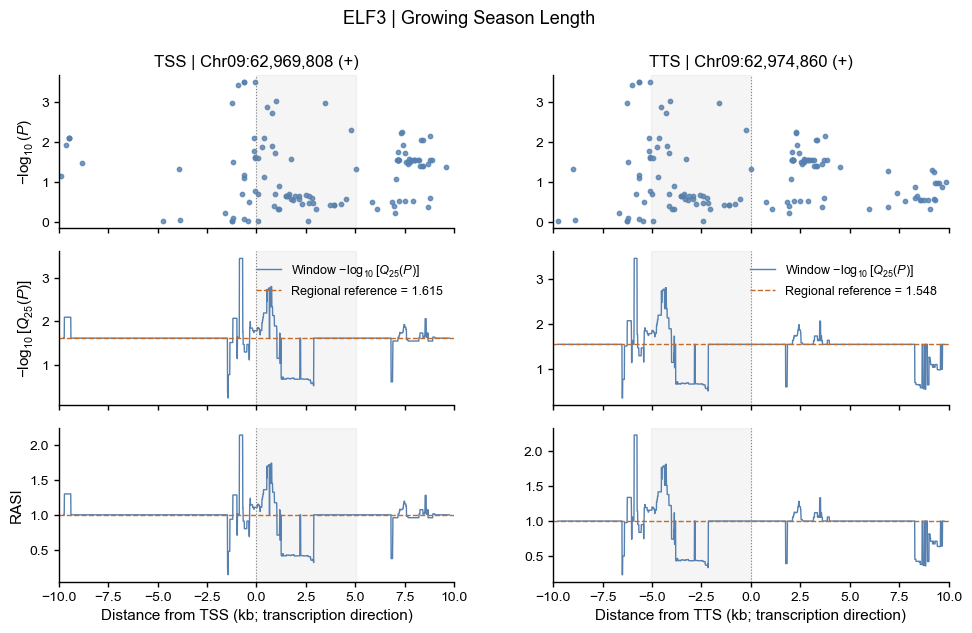

In [5]:
prefix = example_prefixes['ELF3']
elf3_rasi_plot = plot_rasi_example(
    f'{prefix}.sites.csv.gz', f'{prefix}.windows.csv.gz', f'{prefix}.summary.csv.gz',
    f'{prefix}.example', figsize=(10, 6.5),
)
plt.show()


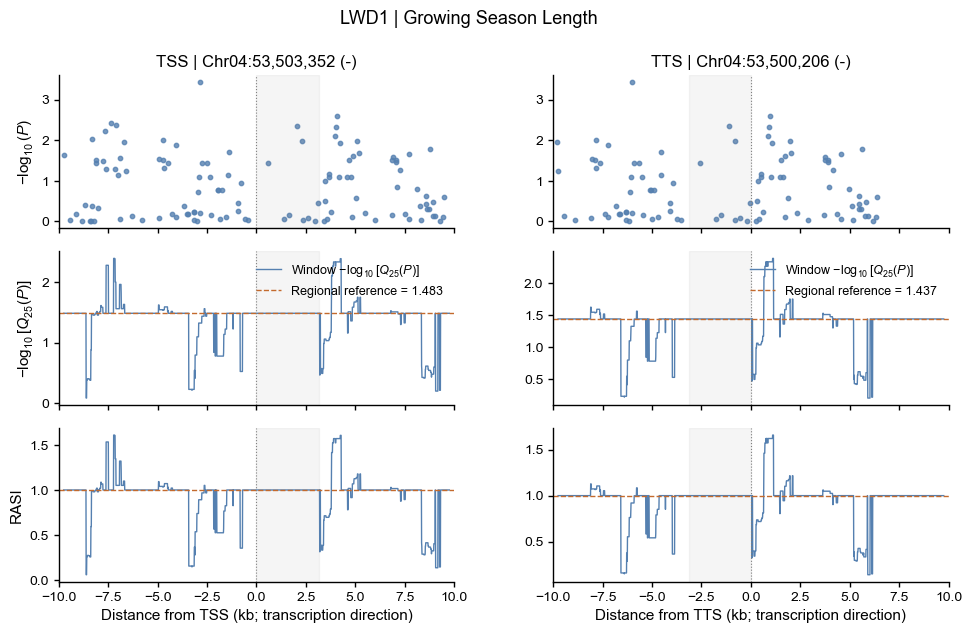

In [6]:
prefix = example_prefixes['LWD1']
lwd1_rasi_plot = plot_rasi_example(
    f'{prefix}.sites.csv.gz', f'{prefix}.windows.csv.gz', f'{prefix}.summary.csv.gz',
    f'{prefix}.example', figsize=(10, 6.5),
)
plt.show()


## 2. Promoter mutation effects and high-effect index

Use barcode-level promoter mutagenesis data from Groover et al. (2026) for PsbS, Raf1 and SBPase to estimate individual mutation effects and their spatial distribution. Constructs often contain multiple mutations; fit an additive linear model with an intercept to log₂ expression read ratios. Retain reliably mapped barcodes, exclude forbidden mutations and missing expression, and use sparse least squares to infer mutation coefficients.


## 2. 启动子突变效应与高效应指数

使用Groover等（2026）提供的PsbS、Raf1和SBPase的barcode-level启动子突变数据，估计单突变效应及其空间分布。构建体常携带多个突变，因此对log₂表达read ratio拟合带截距的加性线性模型。保留可靠匹配的barcode，排除禁用突变和表达缺失记录，通过稀疏最小二乘推断突变系数。


In [7]:
from src.mutant_effects import (
    prepare_mutation_effects, prepare_mutation_profiles,
    plot_mean_mutation_effects, plot_combined_high_effect_index,
)

mutation_source_dir = f'{source_dir}/Groover_2026_nbt'
mutation_results_dir = f'{results_dir}/mutant_effects'
gene_csvs = {
    'SBPase': f'{mutation_source_dir}/3A_sorghum.csv.gz',
    'Raf1': f'{mutation_source_dir}/3B_sorghum.csv.gz',
    'PsbS': f'{mutation_source_dir}/3C_sorghum.csv.gz',
}
min_barcodes = 1
atol = 1e-8
btol = 1e-8
iter_lim = 3000
force_recompute = False
mean_xlim = (-2000, 250)
mean_window_bp = 100
mean_step_bp = 10
min_obs = 5
index_xlim = (-5000, 1000)
index_window_bp = 500
index_step_bp = 10
high_effect_quantile = 0.95
alpha = 0.5
mean_windows_csv = f'{mutation_results_dir}/mean_mutation_effects.windows.csv.gz'
combined_index_csv = f'{mutation_results_dir}/combined_high_effect_index.csv'
mean_figure_prefix = f'{mutation_results_dir}/mean_mutation_effects'
index_figure_prefix = f'{mutation_results_dir}/combined_high_effect_index'



In [8]:
mutation_effects = prepare_mutation_effects(
    gene_csvs, mutation_results_dir, min_barcodes=min_barcodes,
    atol=atol, btol=btol, iter_lim=iter_lim, force_recompute=force_recompute,
)
mutation_effects['fit_summary'][['gene', 'kept_barcodes', 'mutations', 'mapped_to_tss', 'lsqr_istop', 'lsqr_iterations']]


Single-mutation effects: 100%|██████████| 3/3 [00:00<00:00, 84.58it/s]

[23:07:05] Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/mutant_effects/SBPase.mutation_effects.csv.gz; input-content changes require force_recompute=True.
[23:07:05] Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/mutant_effects/Raf1.mutation_effects.csv.gz; input-content changes require force_recompute=True.
[23:07:05] Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/mutant_effects/PsbS.mutation_effects.csv.gz; input-content changes require force_recompute=True.


,gene,kept_barcodes,mutations,mapped_to_tss,lsqr_istop,lsqr_iterations
0,SBPase,95793,30186,30186,2,1523
1,Raf1,30015,15865,15865,2,1718
2,PsbS,46195,20847,20847,2,1216


### Mean mutation-effect profiles

Plot the mean inferred effect in 100 bp windows advanced by 10 bp, requiring at least five mutations per gene window. The three curves provide a check of the input processing and positional patterns. Shading retains the original mean ± variance display and is not a confidence interval; the gray region starts at −400 bp relative to TSS.


### 平均突变效应曲线

按100 bp窗口、10 bp步长绘制推断效应的均值，每个基因窗口至少包含五个突变。三条曲线用于检查数据处理及位置分布模式。阴影保留原图的均值±方差形式，不是置信区间；灰色区域起于TSS上游400 bp。


In [9]:
mutation_profiles = prepare_mutation_profiles(
    mutation_effects['effect_files'], mutation_results_dir,
    mean_xlim=mean_xlim, mean_window_bp=mean_window_bp, mean_step_bp=mean_step_bp,
    min_obs=min_obs, index_xlim=index_xlim, index_window_bp=index_window_bp,
    index_step_bp=index_step_bp, high_effect_quantile=high_effect_quantile,
    alpha=alpha, force_recompute=force_recompute,
)
pd.read_csv(mutation_profiles['summary'])


[23:07:05] Reusing mutation profiles; changed effect-table contents require force_recompute=True.


,gene,mutations,high_effect_mutations,abs_effect_threshold
0,PsbS,20847,1043,0.751319
1,Raf1,15865,794,1.170793
2,SBPase,30186,1510,0.671548


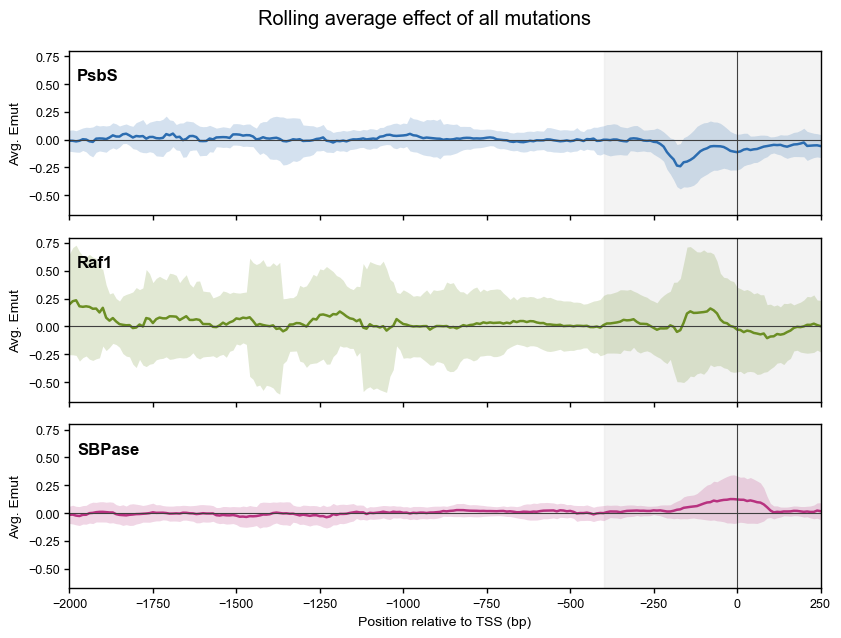

In [10]:
mean_effect_plot = plot_mean_mutation_effects(
    mean_windows_csv, mean_figure_prefix, xlim=mean_xlim,
    spread='variance', figsize=(8.5, 6.5),
)
plt.show()


### High-effect mutation index

Within each gene, classify mutations at or above the 95th percentile of absolute inferred effect as high-effect, including ties and both expression-increasing and expression-decreasing effects. Use 500 bp windows advanced by 10 bp. For each gene, the background includes all mutations with valid effects and TSS positions, extending beyond the displayed range.

For a window, pool high-effect counts $k_g$ and mutation counts $n_g$ across genes with at least five mutations. With pseudocount $\alpha=0.5$, the combined index is

$$I_w=\frac{(\sum_g k_g+\alpha)/(\sum_g n_g+2\alpha)}{\sum_g n_g p_g/\sum_g n_g},\qquad p_g=\frac{K_g+\alpha}{N_g+2\alpha}.$$

Here $K_g$ and $N_g$ are gene-wide high-effect and total mutation counts. Window-specific mutation counts weight the gene backgrounds. Values above or below 1 indicate relative enrichment or depletion of experimentally inferred high-effect mutations.


### 高效应突变指数

在每个基因内，将推断效应绝对值达到或超过第95百分位数的突变定义为高效应，包含阈值处并列值及提高或降低表达的效应。使用500 bp窗口、10 bp步长。各基因背景包含全部效应及TSS位置有效的突变，不限于展示范围。

对于各窗口，合并至少包含五个突变的基因的高效应计数$k_g$及突变计数$n_g$。采用伪计数$\alpha=0.5$，合并指数为

$$I_w=\frac{(\sum_g k_g+\alpha)/(\sum_g n_g+2\alpha)}{\sum_g n_g p_g/\sum_g n_g},\qquad p_g=\frac{K_g+\alpha}{N_g+2\alpha}.$$

其中$K_g$和$N_g$为各基因全部高效应及总突变数，以窗口内突变数对基因背景加权。指数高于或低于1，分别表示实验推断高效应突变的相对富集或缺失。


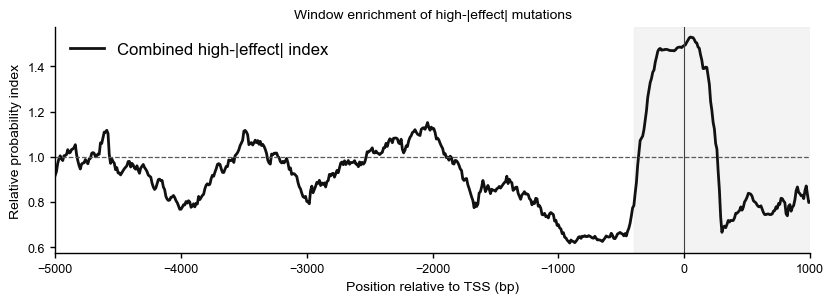

In [11]:
high_effect_plot = plot_combined_high_effect_index(
    combined_index_csv, index_figure_prefix, xlim=index_xlim, figsize=(8.5, 3.2),
)
plt.show()


## 3. Gene-set spatial profiles

Compare the strongest 5% of MAGMA gene associations with equally sized random sets from the remaining eligible genes. Use a fixed-count rule: sort by gene P value and take the first floor(0.05 × number of eligible genes), without expanding ties. Draw 1,000 random sets without replacement within each set; use the same sets for every track and anchor. At each window center, their mean profiles define the empirical 90% interval (5th–95th percentiles). RASI above or below this interval indicates enrichment or depletion relative to the random-set reference.


## 3. 基因集合的空间分布

比较MAGMA关联最强的5%基因与其余有效基因中抽取的等大小随机集合。采用固定数量规则：按基因P值排序，取前floor(0.05 × 有效基因数)个基因，不扩展阈值处并列值。抽取1,000组随机基因，每组内无放回，同一批随机集合用于所有轨道和锚点。各窗口中心的随机均值分布定义经验90%区间（第5–95百分位）。RASI高于或低于该区间，分别表示相对于随机集合参照的富集或缺失。


### 3.1 Gene-centered track definitions

Profiles use 500 bp windows with a 10 bp step around TSS/TTS, aligned in transcription direction. RASI retains its percentile and window conventions defined above. For π, LD and coverage, full windows extending beyond chromosome boundaries retain missing values.

- **RASI** uses the transformed raw-P percentile ratio and the window alignment defined above; sparse windows retain the neutral reference value 1.
- **Nucleotide diversity (π)** is calculated from unfiltered landrace genotypes as per-base pairwise diversity across the full window. Windows without variant records have π=0; MAF filtering is not applied.
- **ACR and UMR coverage** is the fraction of window bases covered by the union of annotation intervals. Overlapping intervals are counted once; project coordinates are 1-based inclusive.
- **LD** is the mean finite pairwise r² between variants in a 500 bp anchor-centered reference window and each sliding window, using QC genotypes. Identical-site pairs are excluded; windows without usable pairs retain missing values.

The high-effect promoter mutation index is the fixed TSS-only curve derived above, without a random-gene interval. Gene/UTR length bars describe the selected genes; UTR lengths retain the first annotated transcript definition.


### 3.1 基因周围轨道的定义

各profile在TSS/TTS周围采用500 bp窗口、10 bp步长，沿转录方向对齐。RASI沿用前述百分位数及窗口口径；π、LD及覆盖比例轨道的完整窗口若超出染色体边界，则保留缺失值。

- **RASI**采用前述原始P值百分位数变换后的比值及窗口对齐方式；位点不足的窗口保留中性参照值1。
- **核苷酸多样性（π）**使用未过滤MAF的地方品种基因型，按完整窗口长度计算每碱基成对多样性，无变异记录的窗口π=0。
- **ACR和UMR覆盖比例**为注释区间并集覆盖的窗口碱基比例，重叠区间不重复计数；项目坐标为1-based闭区间。
- **LD**使用质控基因型，计算500 bp锚点中心参照窗口与各滑动窗口中变异之间的有限成对r²均值，排除同位点自身配对，无有效配对时保留缺失值。

高效应启动子突变指数为前述固定的TSS曲线，不计算随机基因区间。基因及UTR长度色带描述选中的基因，UTR长度保留第一条注释转录本的定义。


In [12]:
from src.gene_profiles import (
    prepare_spatial_profile_database, prepare_gene_set_profiles,
    plot_gene_set_profiles, DEFAULT_PLOT_CONFIG,
)

env_ids = ['bio18', 'gsl', 'al', 'striga']
env_metadata_df = pd.read_csv(f'{source_dir}/envir_metadata.csv').set_index('env_id')
gff_file = f'{source_dir}/Sbicolor_730_v5.1.gene_exons.gff3.gz'
genome_fasta_file = f'{source_dir}/Sbicolor_730_v5.0.fa.gz'
qc_vcf_file = f'{results_dir}/landraces_qc_maf0.05_het0.05.vcf.gz'
pi_vcf_file = f'{results_dir}/landraces.vcf.gz'
acr_bed_file = f'{source_dir}/ACRs.v5.bed.gz'
umr_bed_file = f'{source_dir}/UMRs.v5.bed.gz'
profile_dir = f'{sd_dir}/gene_profiles'
profile_manifest = f'{profile_dir}/profile_database.json'
summary_dir = f'{sd_dir}/gene_set_profiles'
association_sources = {
    env: f'{gwas_dir}/{env}/{env}.gemma/{env}.gemma.gwas_df.h5' for env in env_ids
}
magma_sources = {
    env: f'{gwas_dir}/{env}/{env}.magma/{env}.magma.gwas_df.h5' for env in env_ids
}
high_effect_csv = f'{results_dir}/mutant_effects/combined_high_effect_index.csv'
flank = 10000
bin_size = 500
step = 10
min_variants = 4
threads = project_config['resources']['interactive']['cores']
ld_threads = min(4, threads)
bed_zero_based = False
exclude_self = True
min_pairs = 1
force_recompute = False



In [13]:
profile_database = prepare_spatial_profile_database(
    gff_file, association_sources, qc_vcf_file, pi_vcf_file,
    acr_bed_file, umr_bed_file, profile_dir,
    genome_fasta_file=genome_fasta_file,
    flank=flank, bin_size=bin_size, step=step, min_variants=min_variants,
    threads=threads, ld_threads=ld_threads, bed_zero_based=bed_zero_based,
    exclude_self=exclude_self, min_pairs=min_pairs, force_recompute=force_recompute,
)
profile_database


Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/gene_info.gff.h5
[23:07:27] Building spatial profiles for 32160 genes


RASI environments:  50%|█████     | 2/4 [00:00<00:00, 15.43it/s]

Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.RASI.bio18.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TTS.RASI.bio18.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.RASI.gsl.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TTS.RASI.gsl.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.RASI.al.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TTS.RASI.al.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distr

RASI environments: 100%|██████████| 4/4 [00:00<00:00, 15.78it/s]


Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TTS.RASI.striga.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.pi.unfiltered.centered.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TTS.pi.unfiltered.centered.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.LD.centered.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TTS.LD.centered.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.ACR.coverage.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adapta

{'gene_info': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/gene_info.gff.h5',
 'rasi': {'bio18': {'TSS': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.RASI.bio18.h5',
   'TTS': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TTS.RASI.bio18.h5'},
  'gsl': {'TSS': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.RASI.gsl.h5',
   'TTS': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TTS.RASI.gsl.h5'},
  'al': {'TSS': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.RASI.al.h5',
   'TTS': '/lustre/home/dobby/Work/Project

### 3.2 Observed profiles and random-gene intervals

Select eligible MAGMA genes represented in the profile database. Average each track across the selected top genes, ignoring missing values at each position, and calculate the empirical interval from equal-size random-gene means. Display ±5.5 kb around each anchor.


### 3.2 观测曲线与随机基因区间

以profile数据库中具有有效MAGMA结果的基因为受检集合。按位置忽略缺失值，对选中的top基因计算各轨道均值，并从等大小随机基因集合的均值分布中计算经验区间。展示各锚点两侧5.5 kb。


In [14]:
top_gene_quantile = 0.05
random_num = 1000
seed = 42
plot_xlim = (-5500, 5500)
ci_percentiles = (5, 95)
random_batch_size = 8
summary_prefixes = {env: f'{summary_dir}/{env}.gene_set_profiles' for env in env_ids}
figure_prefixes = {env: f'{sd_dir}/{env}.gene_profiles' for env in env_ids}



In [15]:
from tqdm.auto import tqdm

for env_id in tqdm(env_ids, desc='Gene-set spatial summaries'):
    summary_files = prepare_gene_set_profiles(
        profile_manifest, env_id, magma_sources[env_id], high_effect_csv,
        summary_prefixes[env_id], top_gene_quantile=top_gene_quantile,
        random_num=random_num, seed=seed, plot_xlim=plot_xlim,
        ci_percentiles=ci_percentiles, random_batch_size=random_batch_size,
        force_recompute=force_recompute,
    )
    print(summary_files)



Gene-set spatial summaries: 100%|██████████| 4/4 [00:00<00:00, 435.25it/s]

Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_set_profiles/bio18.gene_set_profiles; input-content changes require force_recompute=True.
{'profiles': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_set_profiles/bio18.gene_set_profiles.profiles.csv.gz', 'selection': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_set_profiles/bio18.gene_set_profiles.genes.csv.gz', 'gene_info': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_set_profiles/bio18.gene_set_profiles.top_gene_info.csv.gz', 'metadata': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_set_profiles/bio18.gene_set_profiles.metadata.json'}
Reusing /lustre/home/dobby/Work/Project/functional-g

### 3.3 Spatial landscapes

Blue curves show top-gene means; gray bands show the empirical 90% random-gene intervals. Compare each track with its own reference. The high-effect index describes independent promoter mutagenesis data and is displayed only around TSS.


### 3.3 空间分布图

蓝色曲线表示top基因均值，灰色阴影表示随机基因的经验90%区间。各轨道应相对于自身参照解读。高效应指数来自独立的启动子突变数据，仅在TSS周围展示。


In [31]:
plot_config = dict(DEFAULT_PLOT_CONFIG)
plot_config.update(
    fig_size=(11, 6.5), track_order=['LD', 'pi', 'ACR', 'UMR', 'high_effect_index'],
    show_fig=False, save_fig=False, grid_hspace=0.25, gene_bar_y=0.675, utr_bar_y=0.645
)



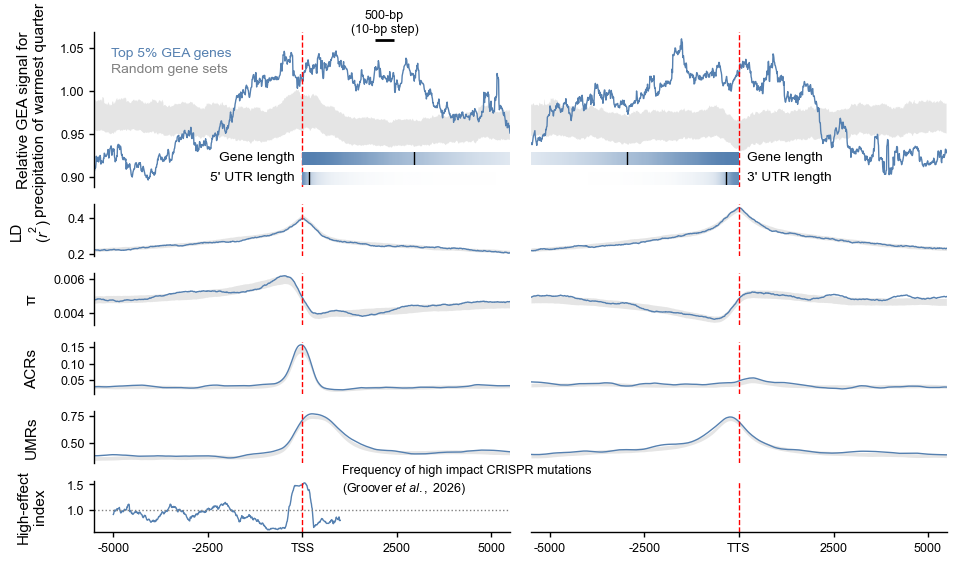

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/bio18.gene_profiles.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/bio18.gene_profiles.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/bio18.gene_profiles.csv.gz'}


In [32]:
env_id = 'bio18'
bio18_profile_plot = plot_gene_set_profiles(
    summary_prefixes[env_id], env_metadata_df.loc[env_id, 'description'],
    figure_prefixes[env_id], config=plot_config,
)
plt.show()
print(bio18_profile_plot['files'])


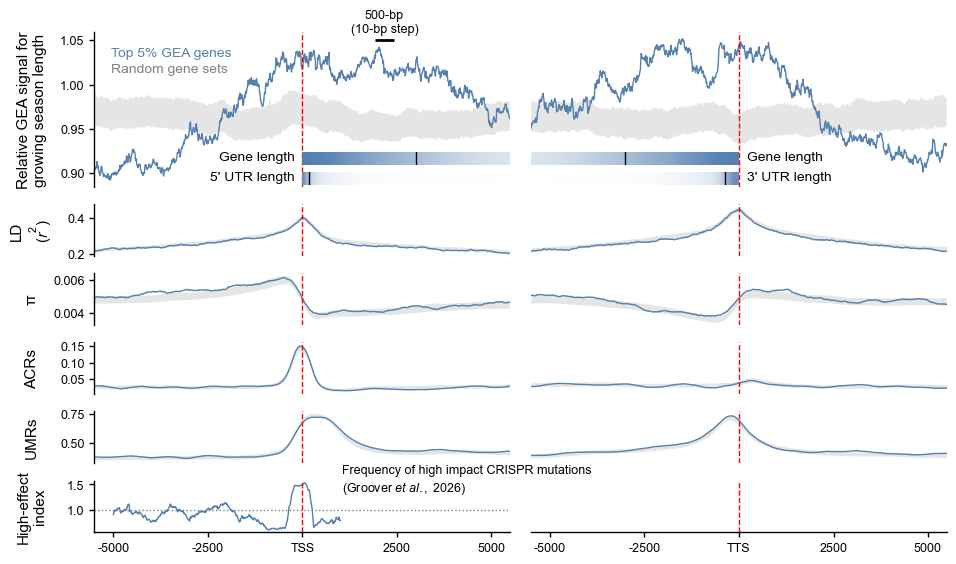

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gsl.gene_profiles.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gsl.gene_profiles.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gsl.gene_profiles.csv.gz'}


In [33]:
env_id = 'gsl'
gsl_profile_plot = plot_gene_set_profiles(
    summary_prefixes[env_id], env_metadata_df.loc[env_id, 'description'],
    figure_prefixes[env_id], config=plot_config,
)
plt.show()
print(gsl_profile_plot['files'])


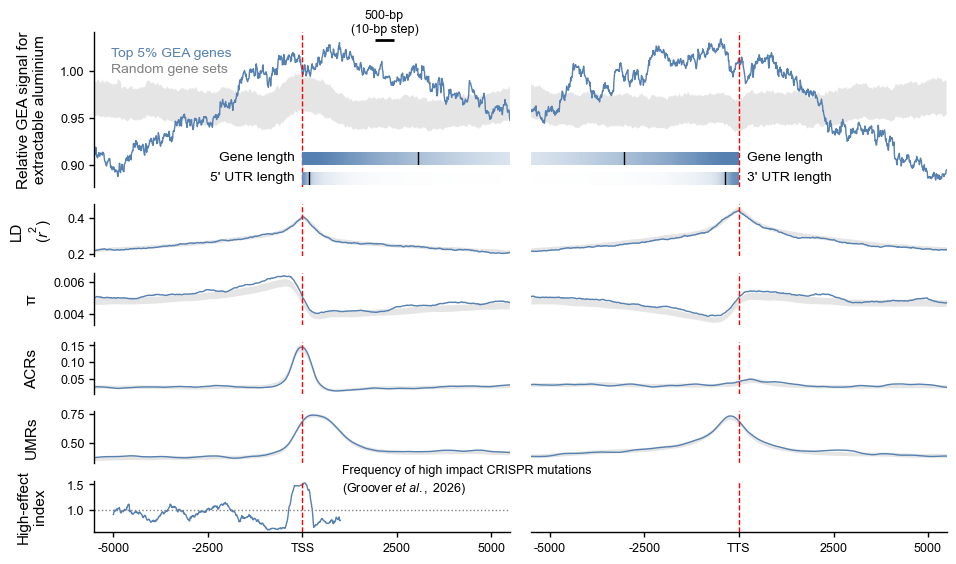

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/al.gene_profiles.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/al.gene_profiles.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/al.gene_profiles.csv.gz'}


In [34]:
env_id = 'al'
al_profile_plot = plot_gene_set_profiles(
    summary_prefixes[env_id], env_metadata_df.loc[env_id, 'description'],
    figure_prefixes[env_id], config=plot_config,
)
plt.show()
print(al_profile_plot['files'])


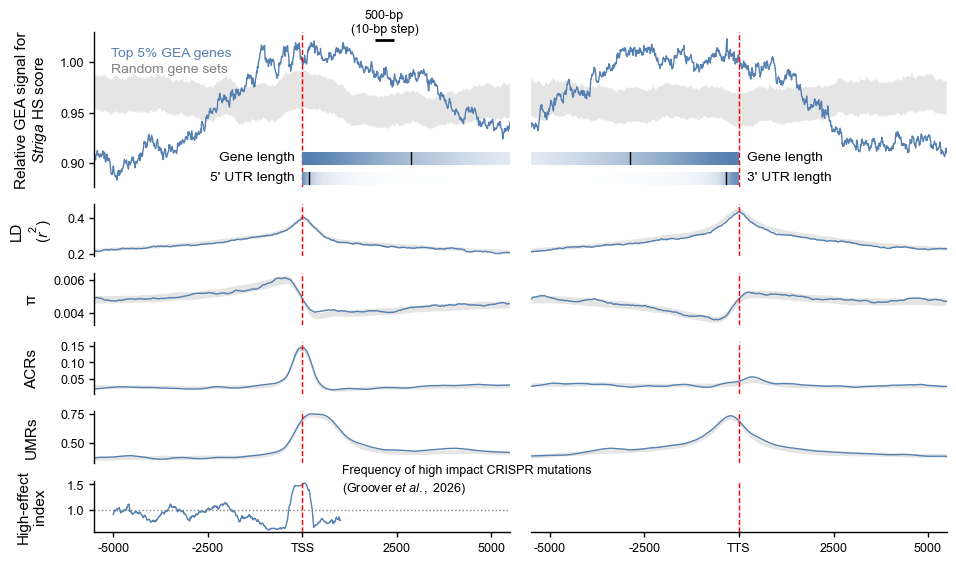

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/striga.gene_profiles.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/striga.gene_profiles.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/striga.gene_profiles.csv.gz'}


In [35]:
env_id = 'striga'
striga_profile_plot = plot_gene_set_profiles(
    summary_prefixes[env_id], env_metadata_df.loc[env_id, 'description'],
    figure_prefixes[env_id], config=plot_config,
)
plt.show()
print(striga_profile_plot['files'])
